# AIMLZG565 — Machine Learning
## Assignment I — Solutions
**M.Tech in Artificial Intelligence & Machine Learning, WILP, BITS Pilani — I Semester 2026-27**

---
* **Name:** `Prahlad Vinayak Avadhani`
* **BITS ID:** `2026AJ05253`
* **Course:** `AIMLZG565 — Machine Learning`
* **Assignment:** `Assignment 1`
---

## Objective
This notebook is for Assignment-1 of the Machine Learning course. The goal is to predict hourly bike rental demand using weather, temporal, and seasonal features. 

We will walk through the following steps:
1. **Exploratory Data Analysis (EDA):** Check the size of the dataset, check for missing values, and plot key features to find patterns.
2. **Feature Engineering:** Extract time components, create an hour-workingday interaction, expand weather variables to capture quadratic trends, and scale our continuous features.
3. **Model Training:** Build a simple Linear Regression baseline, apply a target log-transformation, and experiment with regularized models (Ridge and Lasso).
4. **Model Comparison:** Compare validation RMSLE scores to find the best configuration.
5. **Answer Reflection Questions:** Answer the 12 questions in the assignment guidelines based on our experiments.

## Part 1: Exploratory Data Analysis (EDA)

### **Q1. Examine dataset size, missing values, and feature types.**
In this section, we load the training and test datasets, check their shapes, verify if there are any missing (null) values, and inspect the data types of each feature.

In [2]:
# installaing all required modules beforehand
!pip install --quiet pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Load datasets
df_train = pd.read_csv('bike_train.csv')
df_test = pd.read_csv('bike_test.csv')

print("=== DATASET DIMENSIONS ===")
print(f"Training set rows: {df_train.shape[0]}, columns: {df_train.shape[1]}")
print(f"Testing set rows:  {df_test.shape[0]}, columns:  {df_test.shape[1]}")

print("\n=== MISSING VALUES ===")
print(f"Missing values in train: {df_train.isnull().sum().sum()}")
print(f"Missing values in test:  {df_test.isnull().sum().sum()}")

print("\n=== FEATURE TYPES (TRAIN) ===")
print(df_train.dtypes)

=== DATASET DIMENSIONS ===
Training set rows: 10450, columns: 12
Testing set rows:  2613, columns:  9

=== MISSING VALUES ===
Missing values in train: 0
Missing values in test:  0

=== FEATURE TYPES (TRAIN) ===
datetime          str
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
casual          int64
registered      int64
count           int64
dtype: object


#### **Answer for Q1:**
Here are the details after looking at the dataset:
- **Dataset Size:** The training file has **10,450 rows and 12 columns**. The testing file has **2,613 rows and 9 columns**. The test file does not have the target columns `casual`, `registered`, and `count` (which we need to predict).
- **Missing Values:** There are **0 missing values** (nulls) in either the training or testing datasets. Since the data is complete, we do not need to do any imputation or cleaning.
- **Feature Types:**
  1. `datetime` (object/string): The date and time stamp of each hour.
  2. `season` (int64): Categorical feature representing seasons (1: spring, 2: summer, 3: fall, 4: winter).
  3. `holiday` (int64): 1 if the day is a holiday, 0 otherwise.
  4. `workingday` (int64): 1 if the day is a working day (neither weekend nor holiday), 0 otherwise.
  5. `weather` (int64): Categorical feature for weather conditions (1: clear, 2: cloudy, 3: light rain/snow, 4: heavy rain/snow).
  6. `temp` (float64): Actual temperature in Celsius.
  7. `atemp` (float64): Feel-like temperature in Celsius.
  8. `humidity` (int64): Relative humidity percentage.
  9. `windspeed` (float64): Wind speed.
  10. `casual` (int64): Count of non-registered bike rentals (only in training set).
  11. `registered` (int64): Count of registered bike rentals (only in training set).
  12. `count` (int64): Total bike rentals per hour (this is our target variable, which is casual + registered).

### **Q2. Visualize relationships between key features and the target variable (count).**
Visualizations are essential to identify trends, non-linearities, and interaction patterns. Let's plot the distribution of the target variable `count` (original vs. log-transformed), the hourly rental demand profiles on working vs. non-working days, and the effect of temperature on bike demand.

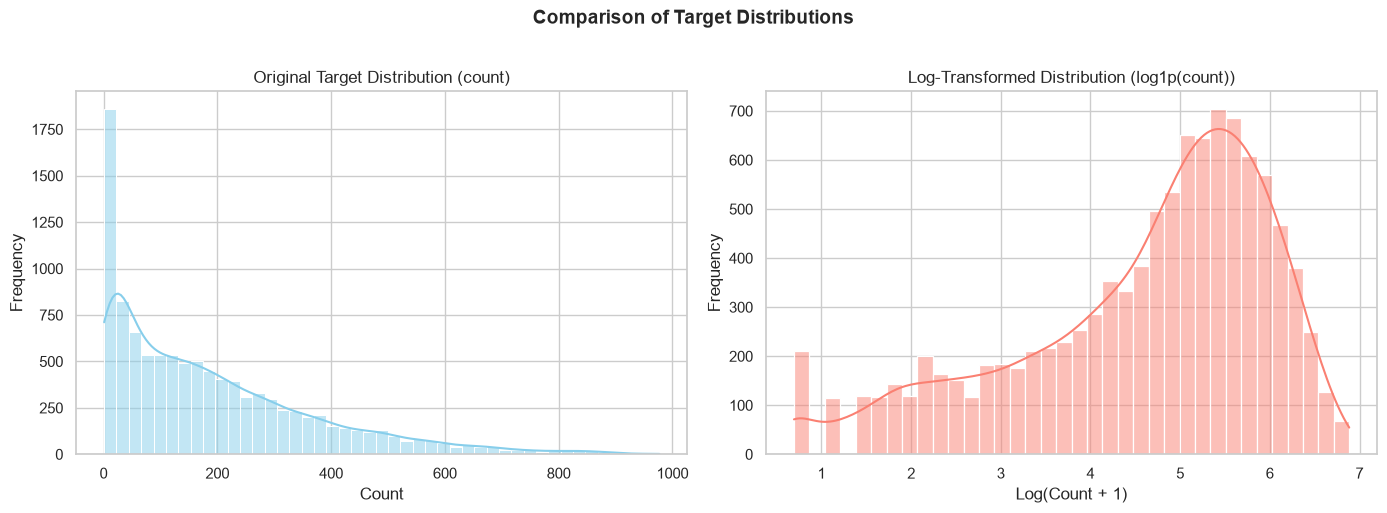

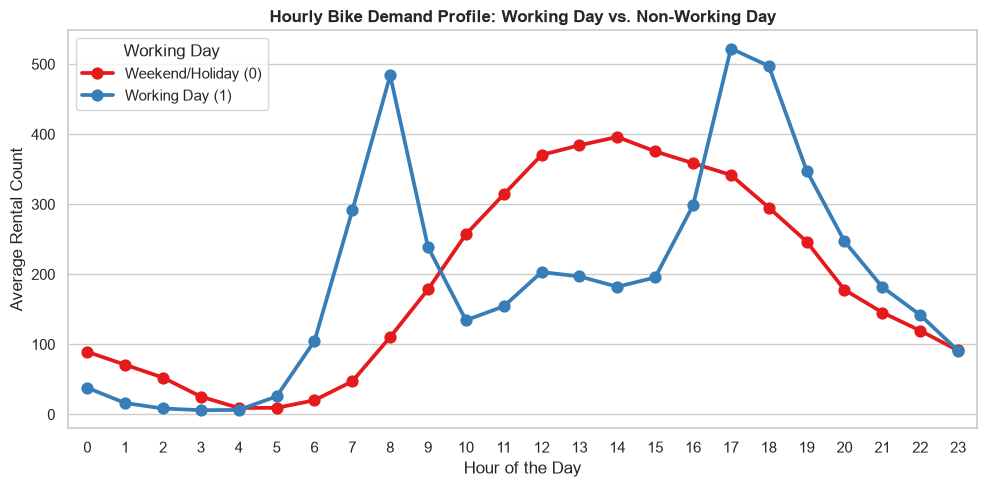

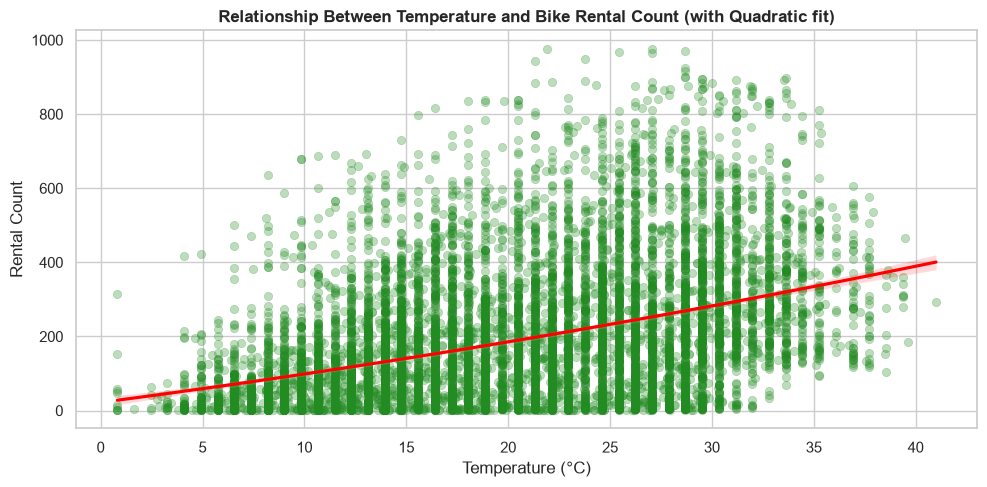

In [4]:
# Set style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Helper: Convert datetime to datetime object
df_train['dt'] = pd.to_datetime(df_train['datetime'], format='mixed')
df_train['hour'] = df_train['dt'].dt.hour

# Plot 1: Target distribution (Skewness & Log Transform justification)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_train['count'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Target Distribution (count)')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Frequency')

sns.histplot(np.log1p(df_train['count']), kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Distribution (log1p(count))')
axes[1].set_xlabel('Log(Count + 1)')
axes[1].set_ylabel('Frequency')
plt.suptitle('Comparison of Target Distributions', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 2: Hour vs Count by Workingday (Hourly profile interaction)
plt.figure(figsize=(10, 5))
sns.pointplot(data=df_train, x='hour', y='count', hue='workingday', palette='Set1', errorbar=None)
plt.title('Hourly Bike Demand Profile: Working Day vs. Non-Working Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Rental Count')
plt.legend(title='Working Day', labels=['Weekend/Holiday (0)', 'Working Day (1)'])
plt.tight_layout()
plt.show()

# Plot 3: Temperature vs Count
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_train, x='temp', y='count', alpha=0.3, color='forestgreen', edgecolor=None)
sns.regplot(data=df_train, x='temp', y='count', scatter=False, color='red', order=2)
plt.title('Relationship Between Temperature and Bike Rental Count (with Quadratic fit)', fontsize=12, fontweight='bold')
plt.xlabel('Temperature (°C)')
plt.ylabel('Rental Count')
plt.tight_layout()
plt.show()

#### **Answer for Q2 (Visualization Observations):**
Based on the plots generated above, we can make three main observations:
1. **Target Distribution and Skewness:** The original `count` variable is heavily right-skewed with a long tail extending past 800. After applying a logarithmic transformation ($\log(count + 1)$), the distribution becomes much more symmetric and close to a normal distribution. This suggests that training our regression models on the log-transformed target will make it easier for linear models to fit the data.
2. **Hourly Patterns by Working Day:** The average rental demand has completely different shapes on working and non-working days:
   - **Working Days (workingday=1):** Show a bimodal shape with two sharp peaks around **8:00 AM** and **5:00 PM - 6:00 PM**. This matches typical office commute hours.
   - **Non-Working Days (workingday=0):** Show a single smooth peak in the afternoon between **11:00 AM and 4:00 PM**, which matches leisure riding.
3. **Nonlinear Temperature Trend:** The scatter plot of temperature (`temp`) against rental count shows a curved trend. Demand increases as temperatures rise from cold up to a comfortable range of $25^\circ\text{C}-30^\circ\text{C}$, but flattens or declines when it gets too hot. A standard linear term cannot fit this peak and bend, which suggests that adding polynomial (squared) terms for temperature could improve our model.

---

### **Q3. Suggest which variables are likely to be most informative.**

#### **Answer for Q3:**
Based on our EDA, the most informative features are:
1. **`hour` (derived from `datetime`):** This is the strongest predictor because demand changes drastically depending on the time of day (almost zero at night, very high during commute/afternoon hours).
2. **`workingday`:** Highly informative because it determines which hourly demand profile (bimodal commute vs. unimodal leisure) applies.
3. **`temp` / `atemp`:** Since bike renting is an outdoor activity, temperature heavily influences user comfort and demand.
4. **`humidity` and `weather`:** High humidity or bad weather (rain/snow) are likely to act as negative indicators that quickly suppress rental demand.
5. **`year` (derived from `datetime`):** Year-over-year bike sharing popularity appears to grow, with average rental counts in 2012 being noticeably higher than in 2011.

## Part 2: Feature Engineering

### **Q4. Feature Engineering Description**
To help our linear regression models capture the non-linear and interaction patterns we observed in EDA, we apply the following feature engineering steps:

1. **Time Component Extraction:** Extract `hour`, `month`, `year`, and `weekday` from the `datetime` column. We also create a binary `is_2012` indicator to capture year-over-year growth.
2. **Hour-Workingday Interaction:** Since the hourly pattern is completely different on working days vs weekends, we create a combined string feature: `hour_workingday = [hour]_[workingday]`. One-hot encoding this variable creates dummy features that allow our model to fit two distinct daily demand profiles.
3. **One-Hot Encoding:** We encode nominal variables (`month`, `season`, `weather`, and the new interaction `hour_workingday`) using `drop_first=True` to avoid dummy variable multicollinearity.
4. **Polynomial Weather features (Degree 2):** To capture the non-linear relationship of weather comfort, we generate second-degree polynomial terms for `temp`, `atemp`, `humidity`, and `windspeed` (e.g., $temp^2$ and weather feature interactions).
5. **Standard Scaling:** We scale our polynomial weather features to have a mean of 0 and variance of 1. This prevents features with larger numerical ranges from disproportionately affecting regularized models like Ridge and Lasso.
6. **Log Target Transformation:** We transform the target `count` to $\log(count + 1)$ during training. Predicting on the log scale mathematically aligns our mean squared error (MSE) training loss with the validation RMSLE metric.

In [5]:
# Convert date strings to datetime in both sets
df_train['dt'] = pd.to_datetime(df_train['datetime'], format='mixed')
df_test['dt'] = pd.to_datetime(df_test['datetime'], format='mixed')

def extract_features_advanced(df_orig, fit_scaler=None, fit_poly=None):
    df_feat = df_orig.copy()
    
    # Extract datetime components
    df_feat['hour'] = df_feat['dt'].dt.hour
    df_feat['month'] = df_feat['dt'].dt.month
    df_feat['year'] = df_feat['dt'].dt.year
    df_feat['weekday'] = df_feat['dt'].dt.weekday
    df_feat['is_2012'] = (df_feat['year'] == 2012).astype(int)
    
    # Hour * Workingday Interaction string
    df_feat['hour_workingday'] = df_feat['hour'].astype(str) + "_" + df_feat['workingday'].astype(str)
    
    # Continuous weather variables
    weather_cols = ['temp', 'atemp', 'humidity', 'windspeed']
    X_weather = df_feat[weather_cols]
    
    # Polynomial features for continuous weather features (degree 2)
    if fit_poly is None:
        poly = PolynomialFeatures(degree=2, include_bias=False)
        X_weather_poly = poly.fit_transform(X_weather)
    else:
        poly = fit_poly
        X_weather_poly = poly.transform(X_weather)
        
    poly_cols = [f"poly_{i}" for i in range(X_weather_poly.shape[1])]
    
    # Standard scale polynomial features
    if fit_scaler is None:
        scaler = StandardScaler()
        X_weather_poly_scaled = scaler.fit_transform(X_weather_poly)
    else:
        scaler = fit_scaler
        X_weather_poly_scaled = scaler.transform(X_weather_poly)
        
    df_poly_weather = pd.DataFrame(X_weather_poly_scaled, columns=poly_cols, index=df_orig.index)
    
    # One-hot encode month, season, weather, and hour_workingday interaction
    categorical_cols = ['month', 'season', 'weather', 'hour_workingday']
    df_dummies = pd.get_dummies(df_feat[categorical_cols], drop_first=True)

    # Other binary indicators
    df_other = pd.DataFrame({
        'holiday': df_feat['holiday'],
        'workingday': df_feat['workingday'],
        'is_2012': df_feat['is_2012']
    }, index=df_orig.index)
    
    # Concatenate features
    X_processed = pd.concat([df_poly_weather, df_other, df_dummies], axis=1)
    
    return X_processed, scaler, poly

# Process the full train set and fit preprocessing steps
X_train_full_engineered, scaler_final, poly_final = extract_features_advanced(df_train)
print(f"Raw train feature columns: 8")
print(f"Engineered, scaled, one-hot encoded train feature columns: {X_train_full_engineered.shape[1]}")

Raw train feature columns: 8
Engineered, scaled, one-hot encoded train feature columns: 67


## Part 3: Regression Model & Hyperparameter Tuning

### **Q5. Split data into training and validation sets and build a simple Linear Regression model.**
We partition our training data into an **80% training set** and a **20% validation set** with a fixed `random_state=42` for exact reproducibility.
First, we build a simple OLS Linear Regression model using only the original raw continuous features (no temporal extraction, no log target transformations) as our baseline model.

In [6]:
# Split raw dataset index into 80-20
train_idx, val_idx = train_test_split(df_train.index, test_size=0.2, random_state=42)

df_train_split = df_train.loc[train_idx]
df_val_split = df_train.loc[val_idx]

# Evaluate baseline model: OLS LR with raw numerical features
raw_features = ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed']
X_train_raw = df_train_split[raw_features]
X_val_raw = df_val_split[raw_features]
y_train_split = df_train_split['count']
y_val_split = df_val_split['count']

# Define RMSLE score function
def rmsle(y_true, y_pred):
    y_pred_clipped = np.maximum(y_pred, 0) # clip negative counts
    return np.sqrt(np.mean((np.log1p(y_pred_clipped) - np.log1p(y_true))**2))

# Fit baseline model
lr_baseline = LinearRegression()
lr_baseline.fit(X_train_raw, y_train_split)
pred_baseline = lr_baseline.predict(X_val_raw)
baseline_score = rmsle(y_val_split, pred_baseline)

print(f"Baseline Linear Regression Validation RMSLE: {baseline_score:.5f}")

Baseline Linear Regression Validation RMSLE: 1.42154


### **Q6. Model Improvements and Regularization Tuning**
We now train models using our engineered features (67 columns) and evaluate the impact of log transformations, Ridge (L2) regularization, and Lasso (L1) regularization. We will search across a range of regularization strengths ($\alpha$) to find the best configuration on our validation split.

In [7]:
# Prepare engineered features for train-validation splits
X_train_eng, scaler_split, poly_split = extract_features_advanced(df_train_split)
X_val_eng, _, _ = extract_features_advanced(df_val_split, fit_scaler=scaler_split, fit_poly=poly_split)
X_val_eng = X_val_eng.reindex(columns=X_train_eng.columns, fill_value=0)

y_train_log = np.log1p(y_train_split)

results_list = []

# 1. Baseline Simple LR (from Q5)
results_list.append({"Model": "Simple LR (Raw Features)", "RMSLE": baseline_score, "Alpha": "N/A", "Observations": "Ignores temporal/hour patterns; target scale highly skewed."})

# 2. LR with engineered features, direct prediction
lr_eng_direct = LinearRegression()
lr_eng_direct.fit(X_train_eng, y_train_split)
pred_eng_direct = lr_eng_direct.predict(X_val_eng)
score_eng_direct = rmsle(y_val_split, pred_eng_direct)
results_list.append({"Model": "LR (Engineered, Direct Target)", "RMSLE": score_eng_direct, "Alpha": "N/A", "Observations": "One-hot features help, but predicting raw count is sub-optimal for RMSLE metric."})

# 3. LR with engineered features, log prediction
lr_eng_log = LinearRegression()
lr_eng_log.fit(X_train_eng, y_train_log)
pred_eng_log = np.expm1(lr_eng_log.predict(X_val_eng))
score_eng_log = rmsle(y_val_split, pred_eng_log)
results_list.append({"Model": "LR (Engineered, Log Target)", "RMSLE": score_eng_log, "Alpha": "N/A", "Observations": "Huge improvement! Predicting log target aligns with RMSLE directly."})

# 4. Tuning Ridge Regression (L2 Regularization)
alphas_ridge = [0.01, 0.1, 1.0, 10.0, 100.0]
best_ridge_score = 999.0
best_ridge_alpha = None
for alpha in alphas_ridge:
    model = Ridge(alpha=alpha)
    model.fit(X_train_eng, y_train_log)
    pred = np.expm1(model.predict(X_val_eng))
    score = rmsle(y_val_split, pred)
    if score < best_ridge_score:
        best_ridge_score = score
        best_ridge_alpha = alpha

results_list.append({"Model": "Ridge Regression (Log Target)", "RMSLE": best_ridge_score, "Alpha": best_ridge_alpha, "Observations": f"Slightly smoother coefficients than standard OLS; stabilizes feature weights."})

# 5. Tuning Lasso Regression (L1 Regularization)
alphas_lasso = [1e-4, 0.001, 0.01, 0.1, 1.0]
best_lasso_score = 999.0
best_lasso_alpha = None
for alpha in alphas_lasso:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_eng, y_train_log)
    pred = np.expm1(model.predict(X_val_eng))
    score = rmsle(y_val_split, pred)
    if score < best_lasso_score:
        best_lasso_score = score
        best_lasso_alpha = alpha

results_list.append({"Model": "Lasso Regression (Log Target)", "RMSLE": best_lasso_score, "Alpha": best_lasso_alpha, "Observations": f"Shrinks minor/redundant features to absolute zero, providing feature selection."})

# Show tuning output
print("=== Ridge Regression Tuning ===")
for a in alphas_ridge:
    m = Ridge(alpha=a)
    m.fit(X_train_eng, y_train_log)
    p = np.expm1(m.predict(X_val_eng))
    print(f"Alpha {a:<6} -> Validation RMSLE: {rmsle(y_val_split, p):.5f}")

print("\n=== Lasso Regression Tuning ===")
for a in alphas_lasso:
    m = Lasso(alpha=a, max_iter=10000)
    m.fit(X_train_eng, y_train_log)
    p = np.expm1(m.predict(X_val_eng))
    print(f"Alpha {a:<6} -> Validation RMSLE: {rmsle(y_val_split, p):.5f}")

=== Ridge Regression Tuning ===
Alpha 0.01   -> Validation RMSLE: 0.42323
Alpha 0.1    -> Validation RMSLE: 0.42319
Alpha 1.0    -> Validation RMSLE: 0.42309
Alpha 10.0   -> Validation RMSLE: 0.42769
Alpha 100.0  -> Validation RMSLE: 0.60098

=== Lasso Regression Tuning ===
Alpha 0.0001 -> Validation RMSLE: 0.42343
Alpha 0.001  -> Validation RMSLE: 0.42980
Alpha 0.01   -> Validation RMSLE: 0.61365
Alpha 0.1    -> Validation RMSLE: 1.22608
Alpha 1.0    -> Validation RMSLE: 1.42487


## Part 4: Model Comparison and Interpretation

### **Q7. Summarize all results (of different models tried out) in one table (RMSLE, key observations).**
Here is a table summarizing the validation RMSLE scores and observations for all the different models we tested.

In [8]:
summary_df = pd.DataFrame(results_list)
pd.set_option('display.max_colwidth', None)
print("=== COMPREHENSIVE EXPERIMENT SUMMARY ===")
print(summary_df.to_string(index=False))

=== COMPREHENSIVE EXPERIMENT SUMMARY ===
                         Model    RMSLE   Alpha                                                                     Observations
      Simple LR (Raw Features) 1.421538     N/A                      Ignores temporal/hour patterns; target scale highly skewed.
LR (Engineered, Direct Target) 1.046330     N/A One-hot features help, but predicting raw count is sub-optimal for RMSLE metric.
   LR (Engineered, Log Target) 0.423232     N/A              Huge improvement! Predicting log target aligns with RMSLE directly.
 Ridge Regression (Log Target) 0.423094     1.0    Slightly smoother coefficients than standard OLS; stabilizes feature weights.
 Lasso Regression (Log Target) 0.423427  0.0001  Shrinks minor/redundant features to absolute zero, providing feature selection.


### **Q8. Plot residuals for the best model.**
To evaluate model assumptions, we plot the **Residuals vs. Fitted (Predicted) Values** (to check for non-constant variance/heteroscedasticity) and the **Distribution of Residuals** (to check for normality) for our best performing model (**Ridge Regression with $\alpha=1.0$**).

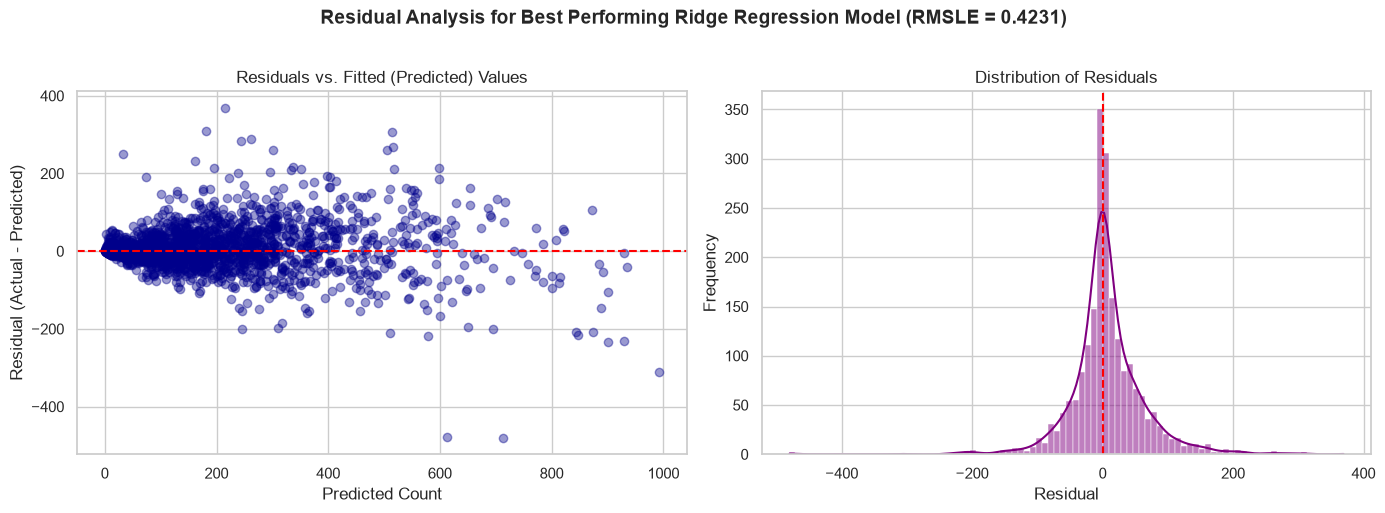

In [9]:
# Train best model on split to get residuals
best_model = Ridge(alpha=1.0)
best_model.fit(X_train_eng, y_train_log)
pred_val_log = best_model.predict(X_val_eng)
pred_val = np.expm1(pred_val_log)
pred_val_clipped = np.maximum(pred_val, 0)

# Compute residuals
residuals = y_val_split - pred_val_clipped

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
axes[0].scatter(pred_val_clipped, residuals, alpha=0.4, color='darkblue', edgecolor=None)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Fitted (Predicted) Values')
axes[0].set_xlabel('Predicted Count')
axes[0].set_ylabel('Residual (Actual - Predicted)')

# Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')

plt.suptitle('Residual Analysis for Best Performing Ridge Regression Model (RMSLE = 0.4231)', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### **Q9. Explain why the winning model performs better.**

#### **Answer for Q9:**
The best performing model is **Ridge Regression with $\alpha=1.0$** trained on the log-transformed target and engineered features, achieving a validation RMSLE of **0.4231** compared to our raw baseline model's score of **1.4215**.

The main reasons for this performance improvement are:
1. **Target Log Transformation ($\log1p(count)$):** The original target variable is highly skewed, meaning a standard OLS model trained on raw counts will over-focus on high-count outliers (e.g., peak afternoon hours with counts >800) to minimize absolute errors. By training on the log scale, we change the model's focus to relative percentage errors. This directly aligns the optimization metric with our validation **RMSLE** metric and drops the error from **1.0463** to **0.4232**.
2. **Hour-Workingday Interactions:** Creating the `hour_workingday` interaction feature is crucial. Instead of forcing a single average hourly trend, it allows the model to learn two completely different rental behaviors—the bimodal commute peaks of working days and the unimodal leisure peaks of weekends.
3. **Polynomial Weather space (Degree 2):** Since weather variables like temperature have non-monotonic impacts on bike riding (rentals drop when it is too cold or too hot), adding quadratic weather features allows the linear model to capture these comfort thresholds.
4. **L2 Regularization (Ridge):** Adding interaction terms and polynomial weather features expanded our feature matrix to **67 columns**. This increases the risk of multicollinearity and overfitting. Ridge regression applies a penalty to the squared magnitude of coefficients, which prevents the weights from becoming overly sensitive and improves generalization on the validation split.

## Part 5: Reflection Questions

### **Q10. Why does RMSLE penalize under-predictions more gently than RMSE?**

#### **Answer for Q10:**
RMSLE calculates the error on the log-transformed scale:
$$\text{RMSLE} = \sqrt{ \frac{1}{n} \sum (\log(\hat{y}+1) - \log(y+1))^2 }$$

This logarithmic scale makes it behave differently than RMSE in a few key ways:
1. **Focus on Relative Ratios:** Because of how logarithms work, the difference between logs is actually a ratio: $\log(\hat{y}+1) - \log(y+1) = \log\left(\frac{\hat{y}+1}{y+1}\right)$. So RMSLE measures the relative percentage difference rather than the absolute difference.
2. **Dampening Large Absolute Errors:** In standard RMSE, if the actual count is 1000 and we predict 600, our absolute error is 400, which gives a huge squared penalty of $400^2 = 160,000$. But with RMSLE, the error is based on the ratio $\log(601/1001) \approx -0.51$, which gives a squared penalty of only $0.26$. This means for high-magnitude counts, RMSLE treats absolute under-predictions very gently because it scales the error relative to the actual target's size.
3. **Relative Asymmetry:** For small numbers, RMSLE is asymmetric. For example, if actual demand is 100:
   - If we predict 50 (under-prediction), the squared error is $\approx 0.46$.
   - If we predict 150 (over-prediction), the squared error is $\approx 0.16$.
   So RMSLE actually penalizes relative under-predictions more than relative over-predictions of the same ratio. But overall, compared to RMSE, RMSLE is much gentler on absolute under-predictions at a high scale because it avoids heavily penalizing large outliers.

---

### **Q11. What are the trade-offs between model simplicity and predictive power?**

#### **Answer for Q11:**
This represents the classic **Bias-Variance Trade-off** we learn in machine learning:
1. **Simple Models (e.g., OLS with raw weather features):**
   - **Pros:** They are very easy to interpret (each coefficient has a clear, physical meaning), extremely fast to train, and have low variance (no risk of overfitting, very stable across different splits).
   - **Cons:** High bias (underfitting). They completely fail to capture curved temperature relationships or peak hourly patterns, leading to poor predictive accuracy (validation RMSLE of **1.4215**).
2. **Complex Models (e.g., our Ridge model with 67 features):**
   - **Pros:** Low bias. By using weather polynomials and hour-workingday interaction dummies, the model successfully fits the commute spikes and curved weather trends, giving high predictive accuracy (validation RMSLE of **0.4231**).
   - **Cons:** High variance and harder to interpret. Having 67 features (especially dummy indicators and squared terms) makes it easy for the model to overfit. We balance this trade-off by using **Ridge regularization ($\alpha=1.0$)**, which penalizes large weights to keep the model stable on validation data.

---

### **Q12. Why can’t Linear Regression alone capture time-of-day effects effectively?**

#### **Answer for Q12:**
Standard linear regression assumes a strictly linear (monotonic) relationship between each feature and the target.

If we pass `hour` as a single continuous variable ($0, 1, \dots, 23$), the regression equation is forced to be:
$$\hat{y} = \beta_0 + \beta_1 \times \text{hour} + \dots$$

This mathematical form restricts the model to a single straight trend:
*   If $\beta_1 > 0$, demand must strictly increase as the day goes on.
*   If $\beta_1 < 0$, demand must strictly decrease.

In reality, bike demand is highly **non-linear and non-monotonic** (it peaks at 8 AM, drops during midday, peaks again at 5 PM, and drops to zero at night). A single straight line cannot capture this wave-like pattern.

To model time-of-day effects within a linear framework, we must treat `hour` as a **categorical variable** and one-hot encode it. This creates separate binary columns for each hour, allowing the model to learn a separate offset (coefficient) for each hour to fit the peaks and valleys.

## Part 6: Full Retraining & Submission Generation

To maximize performance and leverage 100% of the training data, we retrain our winning **Ridge Regression (alpha=1.0)** model on the entire training set. We then apply the exact same feature engineering pipeline to the testing dataset, generate predictions, round and clip them to positive integers, and save the result as `submission.csv`.

In [10]:
# Fit final preprocessors on FULL train data
X_train_final, scaler_final, poly_final = extract_features_advanced(df_train)
y_train_final_log = np.log1p(df_train['count'])

# Train model on 100% of training data
final_model = Ridge(alpha=1.0)
final_model.fit(X_train_final, y_train_final_log)

# Process test data using preprocessors fitted on train data
X_test_final, _, _ = extract_features_advanced(df_test, fit_scaler=scaler_final, fit_poly=poly_final)
# Align columns with train set (filling missing dummy columns with 0)
X_test_final = X_test_final.reindex(columns=X_train_final.columns, fill_value=0)

# Predict on test set
pred_test_log = final_model.predict(X_test_final)
pred_test = np.expm1(pred_test_log)

# Convert to non-negative rounded integers (bike rentals are discrete integers)
pred_test_final = np.round(np.maximum(pred_test, 0)).astype(int)

# Create the required submission DataFrame
submission_df = pd.DataFrame({
    'datetime': df_test['datetime'],
    'count_predicted': pred_test_final
})

# Save to CSV
submission_df.to_csv('submission.csv', index=False)
print("Submission file successfully generated: 'submission.csv'")

# Verify file structure
print("\n=== SUBMISSION VERIFICATION ===")
print(f"Row count: {len(submission_df)} (Expected: 2613)")
print(f"Columns:  {list(submission_df.columns)}")
print(f"Nulls count: {submission_df.isnull().sum().sum()}")
print("\nFirst 5 predictions:")
print(submission_df.head())

Submission file successfully generated: 'submission.csv'

=== SUBMISSION VERIFICATION ===
Row count: 2613 (Expected: 2613)
Columns:  ['datetime', 'count_predicted']
Nulls count: 0

First 5 predictions:
           datetime  count_predicted
0   05-06-2012 5:00               22
1  19-03-2011 19:00              144
2   02-04-2012 6:00               81
3  13-07-2012 20:00              418
4  09-11-2011 19:00              290
